# Лабораторна робота №1. Побудова простої трансформерної моделі
## Частина 3: Розвідувальний аналіз даних, частотний розподіл та попередня обробка корпусу WikiText-2

**Дисципліна:** «Нейромережеві технології і системи»  
**Тема:** «Побудова простої трансформерної моделі»  
**Варіант завдання 2:** Авторегресивна генерація тексту за допомогою Transformer Decoder  
**Досліджуваний корпус:** Набір даних **WikiText-2** (`wikitext-2-raw-v1`)

---

### Постановка задачі авторегресивного моделювання мови

На відміну від класифікації послідовностей, авторегресивне **мовне моделювання (Causal Language Modeling)** полягає в оцінці спільного розподілу ймовірностей послідовності токенів $W = (w_1, w_2, \dots, w_N)$ за правилом ланцюга:
$$P(W) = P(w_1, w_2, \dots, w_N) = \prod_{t=1}^N P(w_t \mid w_1, \dots, w_{t-1})$$

Завдання моделі — **прогнозування наступного токена (Next-Token Prediction)**: на кожному кроці $t$, спираючись на контекст $w_{<t}$, модель обчислює умовний розподіл імовірностей над словником $\mathcal{V}$.

### Специфіка корпусу WikiText-2

Корпус **WikiText-2** є стандартним бенчмарком для навчання мовних моделей і має такі властивості:
1. **Збереження структури тексту:** тексти містять повну пунктуацію, регістр символів, числа та дефісні зв'язки (`@-@`).
2. **Розмітка розділів:** заголовки статей Вікіпедії позначені конструкціями виду `= = Title = =`.
3. **Обсяг:** понад 2.1 млн токенів у навчальній частині зі складною синтаксичною структурою.

### Мета етапу:
* Провести аналіз структури офіційних сплітів (Train, Validation, Test).
* Дослідити емпіричний розподіл частот слів та його відповідність закону Ціпфа на логарифмічній шкалі.
* Побудувати словник розміром 10 000 токенів виключно за навчальною вибіркою та оцінити рівень OOV-токенів.
* Сформувати ковзні вікна фіксованої довжини $L=64$ із цільовим зсувом на один токен ($X \to Y$) без перетину меж сплітів.
* Зберегти сформовані тензори у `data/processed/wikitext_processed.pt`.

In [1]:
import sys
from pathlib import Path
from collections import Counter
import math

# Динамічне визначення кореня проєкту (підтримує як робочий каталог notebooks/, так і корінь проєкту)
current_dir = Path.cwd().resolve()
if (current_dir / "utils.py").exists():
    LAB_ROOT = current_dir
elif (current_dir / ".." / "utils.py").resolve().exists():
    LAB_ROOT = (current_dir / "..").resolve()
else:
    LAB_ROOT = next((p for p in [current_dir, *current_dir.parents] if (p / "utils.py").exists()), current_dir)
if str(LAB_ROOT) not in sys.path:
    sys.path.insert(0, str(LAB_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from utils import (
    PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN,
    PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX,
    tokenize_text, Vocabulary, set_seed, setup_plot_style
)

set_seed(42)
setup_plot_style()

DATA_DIR = LAB_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUTS_DIR = LAB_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
METRICS_DIR = OUTPUTS_DIR / "metrics"

for d in [PROCESSED_DATA_DIR, FIGURES_DIR, METRICS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Середовище EDA WikiText-2 успішно ініціалізовано.")

Середовище EDA WikiText-2 успішно ініціалізовано.


---
## 1. Завантаження офіційних сплітів WikiText-2

Текстові файли `wikitext2_train.txt`, `wikitext2_validation.txt` та `wikitext2_test.txt` завантажуються з директорії `data/raw/`. Фіксуються фізичні розміри файлів, кількість рядків, порожніх відступів та розмічених заголовків.

In [2]:
def load_text_lines(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f.readlines()]
    return lines

train_lines_raw = load_text_lines(RAW_DATA_DIR / "wikitext2_train.txt")
val_lines_raw = load_text_lines(RAW_DATA_DIR / "wikitext2_validation.txt")
test_lines_raw = load_text_lines(RAW_DATA_DIR / "wikitext2_test.txt")

files_summary = pd.DataFrame([
    {
        "Спліт": "Train",
        "Файл": "wikitext2_train.txt",
        "Розмір (KB)": round((RAW_DATA_DIR / "wikitext2_train.txt").stat().st_size / 1024, 1),
        "Всього рядків": len(train_lines_raw),
        "Непорожніх рядків": sum(1 for line in train_lines_raw if line),
        "Порожніх рядків": sum(1 for line in train_lines_raw if not line),
        "Заголовків (= =)": sum(1 for line in train_lines_raw if line.startswith("=") and line.endswith("="))
    },
    {
        "Спліт": "Validation",
        "Файл": "wikitext2_validation.txt",
        "Розмір (KB)": round((RAW_DATA_DIR / "wikitext2_validation.txt").stat().st_size / 1024, 1),
        "Всього рядків": len(val_lines_raw),
        "Непорожніх рядків": sum(1 for line in val_lines_raw if line),
        "Порожніх рядків": sum(1 for line in val_lines_raw if not line),
        "Заголовків (= =)": sum(1 for line in val_lines_raw if line.startswith("=") and line.endswith("="))
    },
    {
        "Спліт": "Test",
        "Файл": "wikitext2_test.txt",
        "Розмір (KB)": round((RAW_DATA_DIR / "wikitext2_test.txt").stat().st_size / 1024, 1),
        "Всього рядків": len(test_lines_raw),
        "Непорожніх рядків": sum(1 for line in test_lines_raw if line),
        "Порожніх рядків": sum(1 for line in test_lines_raw if not line),
        "Заголовків (= =)": sum(1 for line in test_lines_raw if line.startswith("=") and line.endswith("="))
    }
])

print("Огляд файлів корпусу WikiText-2:")
display(files_summary)

train_lines = [l for l in train_lines_raw if l]
val_lines = [l for l in val_lines_raw if l]
test_lines = [l for l in test_lines_raw if l]

Огляд файлів корпусу WikiText-2:


,Спліт,Файл,Розмір (KB),Всього рядків,Непорожніх рядків,Порожніх рядків,Заголовків (= =)
0,Train,wikitext2_train.txt,10682.2,23767,23767,0,6211
1,Validation,wikitext2_validation.txt,1119.8,2461,2461,0,620
2,Test,wikitext2_test.txt,1260.3,2891,2891,0,706


---
## 2. Токенізація та базова статистика довжин рядків

Для розбиття тексту на токени використовується уніфікований вираз `\w+|[^\w\s]`, який відокремлює розділові знаки від слів і зберігає пунктуаційну структуру речень.

In [3]:
train_tokenized_lines = [tokenize_text(line) for line in train_lines]
val_tokenized_lines = [tokenize_text(line) for line in val_lines]
test_tokenized_lines = [tokenize_text(line) for line in test_lines]

train_lens = [len(toks) for toks in train_tokenized_lines]
val_lens = [len(toks) for toks in val_tokenized_lines]
test_lens = [len(toks) for toks in test_tokenized_lines]

def compute_lens_stats(lens_list, split_name):
    s = pd.Series(lens_list)
    desc = s.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    return {
        "Спліт": split_name,
        "Кількість рядків": int(desc["count"]),
        "Всього токенів": sum(lens_list),
        "Середнє": round(desc["mean"], 1),
        "Std": round(desc["std"], 1),
        "Min": int(desc["min"]),
        "25%": int(desc["25%"]),
        "Медіана": int(desc["50%"]),
        "75%": int(desc["75%"]),
        "95%": int(desc["95%"]),
        "Max": int(desc["max"])
    }

line_stats_df = pd.DataFrame([
    compute_lens_stats(train_lens, "Train"),
    compute_lens_stats(val_lens, "Validation"),
    compute_lens_stats(test_lens, "Test"),
])
print("Описова статистика довжин непорожніх рядків у токенах:")
display(line_stats_df)

Описова статистика довжин непорожніх рядків у токенах:


,Спліт,Кількість рядків,Всього токенів,Середнє,Std,Min,25%,Медіана,75%,95%,Max
0,Train,23767,2122137,89.3,84.6,1,9,77,143,246,733
1,Validation,2461,221611,90.0,81.8,1,10,78,146,240,434
2,Test,2891,249691,86.4,84.0,1,9,69,136,243,497


---
## 3. Візуалізація характеристик корпусу

Візуалізується співвідношення обсягів трьох вибірок за кількістю токенів та розподіл довжин непорожніх рядків у корпусі.

findfont: Failed to find font weight semibold for Arial, now using 700.


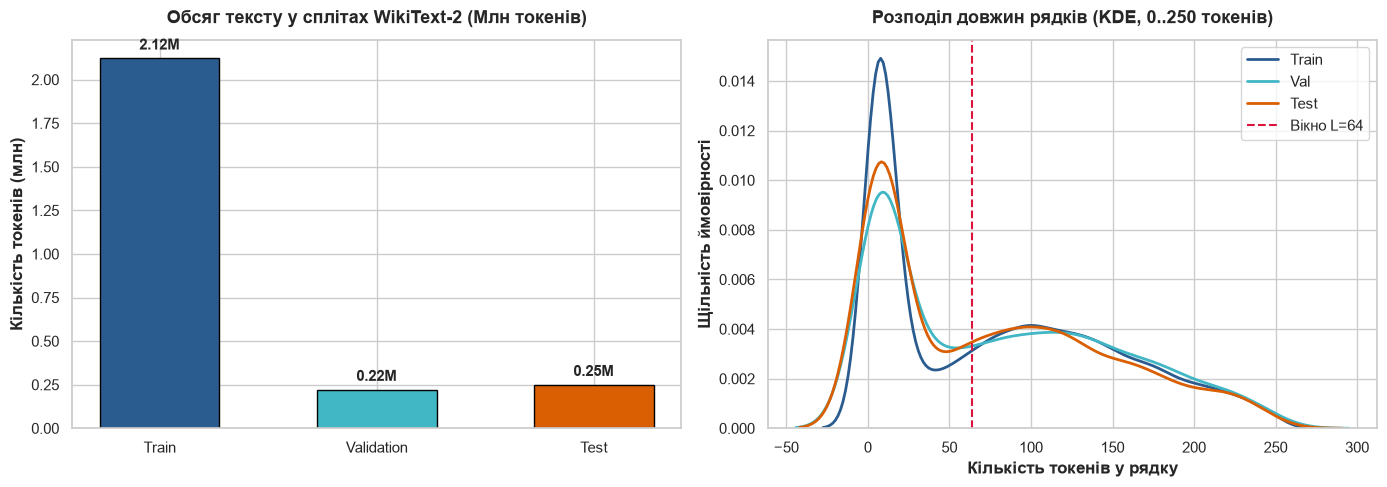

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

splits = line_stats_df["Спліт"].values
tok_counts = line_stats_df["Всього токенів"].values / 1e6
colors = ["#2b5c8f", "#41b6c4", "#d95f02"]

bars = axes[0].bar(splits, tok_counts, color=colors, edgecolor="black", width=0.55)
axes[0].set_title("Обсяг тексту у сплітах WikiText-2 (Млн токенів)", pad=12)
axes[0].set_ylabel("Кількість токенів (млн)")
for bar in bars:
    yval = bar.get_height()
    axes[0].annotate(f"{yval:.2f}M",
                     xy=(bar.get_x() + bar.get_width() / 2, yval),
                     xytext=(0, 4), textcoords="offset points",
                     ha="center", va="bottom", fontweight="bold")

for l_list, s_name, col in zip([train_lens, val_lens, test_lens], ["Train", "Val", "Test"], colors):
    sns.kdeplot([x for x in l_list if x <= 250], ax=axes[1], label=s_name, color=col, linewidth=2)

axes[1].set_title("Розподіл довжин рядків (KDE, 0..250 токенів)", pad=12)
axes[1].set_xlabel("Кількість токенів у рядку")
axes[1].set_ylabel("Щільність ймовірності")
axes[1].axvline(64, color="crimson", linestyle="--", linewidth=1.5, label="Вікно L=64")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_split_sizes.png")
plt.show()

---
## 4. Лексичний аналіз, емпіричний закон Ціпфа та побудова словника

**Закон Ціпфа (Zipf's Law):**  
В емпіричній лінгвістиці частота слова $f(r)$ наближено обернено пропорційна до його рангу $r$ у частотному списку:
$$f(r) \propto \frac{1}{r^{\alpha}} \implies \log f(r) \approx C - \alpha \log r$$
На логарифмічному графіку ($\log \text{рангу}$ проти $\log \text{частоти}$) цей степеневий розподіл проявляється як спадна лінійна залежність із нахилом $\alpha \approx 1$.

Топ-20 найчастіших токенів у навчальній вибірці WikiText-2:


,Ранг,Токен,Кількість,Частка у корпусі (%)
0,1,the,130771,6.16
1,2,",",102624,4.84
2,3,.,84291,3.97
3,4,of,57032,2.69
4,5,and,50738,2.39
5,6,@,45600,2.15
6,7,in,45019,2.12
7,8,to,39522,1.86
8,9,a,36567,1.72
9,10,=,29570,1.39


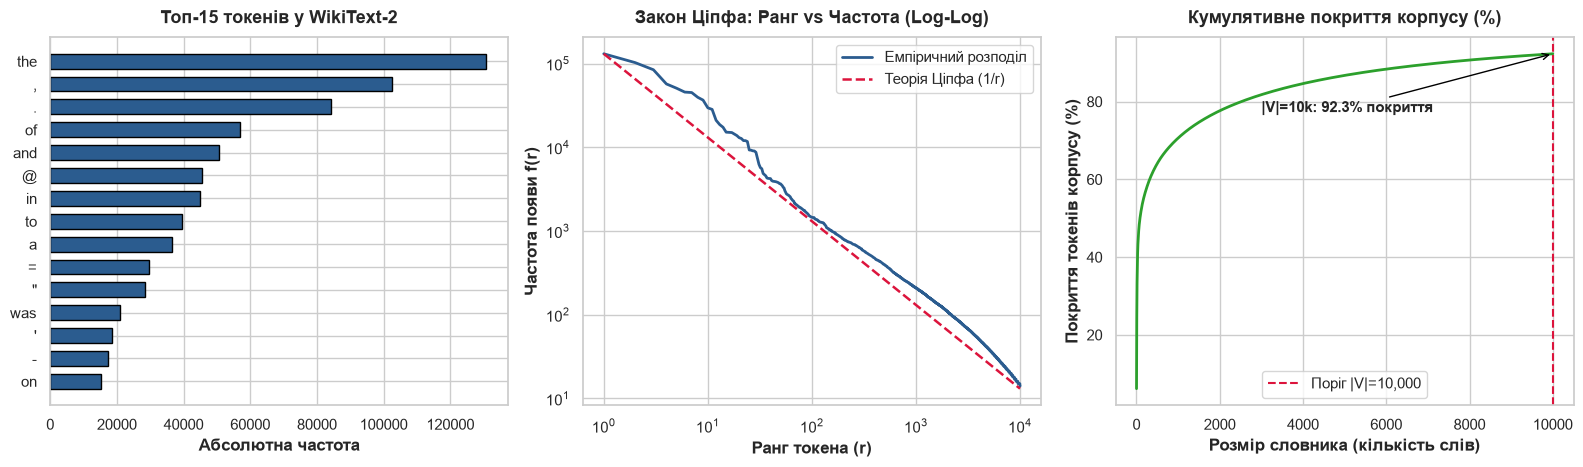


Характеристики сформованого словника:


,Параметр,Значення
0,Унікальних слів у Train,"65,989"
1,Фінальний розмір словника (|V|),"10,000"
2,Мінімальна частота (min_freq),3
3,Спеціальні токени,"<pad>=0, <unk>=1, <bos>=2, <eos>=3"
4,Train UNK Rate,7.69%
5,Validation UNK Rate,9.34%
6,Test UNK Rate,10.21%


In [5]:
all_train_tokens = [tok for toks in train_tokenized_lines for tok in toks]
word_counts = Counter(all_train_tokens)
total_words = len(all_train_tokens)
unique_words = len(word_counts)

top_20 = word_counts.most_common(20)
top_20_df = pd.DataFrame({
    "Ранг": list(range(1, 21)),
    "Токен": [w[0] for w in top_20],
    "Кількість": [w[1] for w in top_20],
    "Частка у корпусі (%)": [round(w[1] / total_words * 100, 2) for w in top_20]
})
print("Топ-20 найчастіших токенів у навчальній вибірці WikiText-2:")
display(top_20_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

words = [w[0] for w in reversed(top_20[:15])]
counts = [w[1] for w in reversed(top_20[:15])]
axes[0].barh(words, counts, color="#2b5c8f", edgecolor="black", height=0.65)
axes[0].set_title("Топ-15 токенів у WikiText-2", pad=10)
axes[0].set_xlabel("Абсолютна частота")

ranks = np.arange(1, min(len(word_counts) + 1, 10001))
freqs = np.array([count for _, count in word_counts.most_common(10000)])

axes[1].plot(ranks, freqs, color="#2b5c8f", lw=2, label="Емпіричний розподіл")
# Теоретична лінія Ціпфа (масштабована під частоту першого слова)
zipf_line = freqs[0] / ranks
axes[1].plot(ranks, zipf_line, color="crimson", linestyle="--", lw=1.8, label="Теорія Ціпфа (1/r)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Закон Ціпфа: Ранг vs Частота (Log-Log)", pad=10)
axes[1].set_xlabel("Ранг токена (r)")
axes[1].set_ylabel("Частота появи f(r)")
axes[1].legend()

cum_freqs = np.cumsum(freqs) / total_words * 100
axes[2].plot(ranks, cum_freqs, color="#2ca02c", lw=2)
axes[2].set_title("Кумулятивне покриття корпусу (%)", pad=10)
axes[2].set_xlabel("Розмір словника (кількість слів)")
axes[2].set_ylabel("Покриття токенів корпусу (%)")
axes[2].axvline(10000, color="crimson", linestyle="--", lw=1.5, label="Поріг |V|=10,000")
cov_10k = cum_freqs[min(9999, len(cum_freqs)-1)]
axes[2].annotate(f"|V|=10k: {cov_10k:.1f}% покриття", xy=(10000, cov_10k),
                 xytext=(3000, cov_10k - 15),
                 arrowprops=dict(arrowstyle="->", color="black"), fontweight="bold")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "wikitext_top_tokens.png")
plt.show()

vocab = Vocabulary.build_from_texts(train_lines, min_freq=3, max_size=10000)

def calculate_unk_rate(tokenized_corpus, vocabulary):
    total = sum(len(line) for line in tokenized_corpus)
    unks = sum(sum(1 for t in line if t not in vocabulary) for line in tokenized_corpus)
    return (unks / total * 100) if total > 0 else 0.0

train_unk = calculate_unk_rate(train_tokenized_lines, vocab)
val_unk = calculate_unk_rate(val_tokenized_lines, vocab)
test_unk = calculate_unk_rate(test_tokenized_lines, vocab)

vocab_summary_df = pd.DataFrame([
    {"Параметр": "Унікальних слів у Train", "Значення": f"{unique_words:,}"},
    {"Параметр": "Фінальний розмір словника (|V|)", "Значення": f"{len(vocab):,}"},
    {"Параметр": "Мінімальна частота (min_freq)", "Значення": 3},
    {"Параметр": "Спеціальні токени", "Значення": "<pad>=0, <unk>=1, <bos>=2, <eos>=3"},
    {"Параметр": "Train UNK Rate", "Значення": f"{train_unk:.2f}%"},
    {"Параметр": "Validation UNK Rate", "Значення": f"{val_unk:.2f}%"},
    {"Параметр": "Test UNK Rate", "Значення": f"{test_unk:.2f}%"}
])
print("\nХарактеристики сформованого словника:")
display(vocab_summary_df)

---
## 5. Підготовка контекстних вікон та авторегресивних цілей (Sequence Windowing)

Для навчання авторегресивного декодера неперервний потік токенів кожного спліту розбивається на послідовні вікна фіксованої довжини $L = 64$.

Для кожного фрагмента з 65 токенів формується пара вхід/ціль довжиною 64 токени зі зсувом на один крок:
$$X = [w_t, w_{t+1}, \dots, w_{t+63}], \quad Y = [w_{t+1}, w_{t+2}, \dots, w_{t+64}]$$

Крок зсуву вікна (stride) дорівнює 64 токенам (вікна не перекриваються). Вікна формуються строго всередині кожного спліту і не перетинають меж між Train, Validation та Test.

In [6]:
SEQ_LEN = 64

def create_causal_sequences(tokenized_lines, vocabulary, seq_len=64):
    flat_tokens = []
    for line in tokenized_lines:
        if line:
            flat_tokens.extend(line)
            flat_tokens.append(EOS_TOKEN)
            
    encoded_ids = vocabulary.encode(flat_tokens)
    
    inputs_list = []
    targets_list = []
    step = seq_len
    for i in range(0, len(encoded_ids) - seq_len, step):
        window = encoded_ids[i : i + seq_len + 1]
        if len(window) == seq_len + 1:
            inputs_list.append(window[:-1])
            targets_list.append(window[1:])
            
    return torch.tensor(inputs_list, dtype=torch.long), torch.tensor(targets_list, dtype=torch.long)

train_inputs, train_targets = create_causal_sequences(train_tokenized_lines, vocab, seq_len=SEQ_LEN)
val_inputs, val_targets = create_causal_sequences(val_tokenized_lines, vocab, seq_len=SEQ_LEN)
test_inputs, test_targets = create_causal_sequences(test_tokenized_lines, vocab, seq_len=SEQ_LEN)

sample_in = train_inputs[0, :8].tolist()
sample_tgt = train_targets[0, :8].tolist()

alignment_df = pd.DataFrame({
    "Позиція": list(range(8)),
    "Input ID": sample_in,
    "Input Слово": [vocab.id2token[i] for i in sample_in],
    "Target ID (Next)": sample_tgt,
    "Target Слово (Next)": [vocab.id2token[i] for i in sample_tgt],
})
print("Ілюстрація зсуву вхідної та цільової послідовностей (Next-Token Shift):")
display(alignment_df)

windows_summary = pd.DataFrame([
    {
        "Спліт": "Train",
        "Кількість вікон": len(train_inputs),
        "Форма Inputs": str(list(train_inputs.shape)),
        "Всього цільових токенів": train_inputs.numel(),
        "Пам'ять (MB)": round((train_inputs.nbytes + train_targets.nbytes) / (1024**2), 2)
    },
    {
        "Спліт": "Validation",
        "Кількість вікон": len(val_inputs),
        "Форма Inputs": str(list(val_inputs.shape)),
        "Всього цільових токенів": val_inputs.numel(),
        "Пам'ять (MB)": round((val_inputs.nbytes + val_targets.nbytes) / (1024**2), 2)
    },
    {
        "Спліт": "Test",
        "Кількість вікон": len(test_inputs),
        "Форма Inputs": str(list(test_inputs.shape)),
        "Всього цільових токенів": test_inputs.numel(),
        "Пам'ять (MB)": round((test_inputs.nbytes + test_targets.nbytes) / (1024**2), 2)
    }
])
print("\nЗведена характеристика сформованих віконних тензорів:")
display(windows_summary)

Ілюстрація зсуву вхідної та цільової послідовностей (Next-Token Shift):


,Позиція,Input ID,Input Слово,Target ID (Next),Target Слово (Next)
0,0,13,=,3876,valkyria
1,1,3876,valkyria,3892,chronicles
2,2,3892,chronicles,887,iii
3,3,887,iii,13,=
4,4,13,=,3,<eos>
5,5,3,<eos>,1,<unk>
6,6,1,<unk>,89,no
7,7,89,no,3876,valkyria



Зведена характеристика сформованих віконних тензорів:


,Спліт,Кількість вікон,Форма Inputs,Всього цільових токенів,Пам'ять (MB)
0,Train,33529,"[33529, 64]",2145856,32.74
1,Validation,3501,"[3501, 64]",224064,3.42
2,Test,3946,"[3946, 64]",252544,3.85


---
## 6. Збереження оброблених даних

Підготовлені тензори вхідних і цільових послідовностей, словник та метадані серіалізуються у файл `data/processed/wikitext_processed.pt`.

In [7]:
processed_wiki_payload = {
    "train_inputs": train_inputs,
    "train_targets": train_targets,
    "val_inputs": val_inputs,
    "val_targets": val_targets,
    "test_inputs": test_inputs,
    "test_targets": test_targets,
    "vocab": vocab.to_dict(),
    "config": {
        "seq_len": SEQ_LEN,
        "vocab_size": len(vocab),
        "seed": 42
    }
}

save_wiki_path = PROCESSED_DATA_DIR / "wikitext_processed.pt"
torch.save(processed_wiki_payload, save_wiki_path)
print(f"[УСПІШНО] Дані WikiText-2 збережено: {save_wiki_path.resolve()}")
print(f"Розмір збереженого бінарного файлу: {save_wiki_path.stat().st_size / (1024*1024):.2f} MB")

[УСПІШНО] Дані WikiText-2 збережено: C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\lab1\data\processed\wikitext_processed.pt
Розмір збереженого бінарного файлу: 40.39 MB


---
## 7. Підсумкові висновки етапу EDA WikiText-2

1. **Характеристика обсягів корпусу:**
   * Навчальний набір містить 23 767 рядків та 2 122 137 токенів (середня довжина рядка — 89.3 токена, медіана — 77).
   * Валідаційний набір містить 2 461 рядок та 221 611 токенів (середня довжина — 90.0 токенів, медіана — 78).
   * Тестовий набір містить 2 891 рядок та 249 691 токен (середня довжина — 86.4 токена, медіана — 69).

2. **Частотний розподіл слів:**
   * У навчальному корпусі зафіксовано 65 989 унікальних слів.
   * На логарифмічному графіку емпіричний розподіл частот демонструє характерну лінійну залежність (Zipf-like pattern), властиву природним мовам. Топ-20 найчастіших службових токенів (на чолі з `the`, `,`, `.`, `of`, `and`) покривають значну частку тексту.

3. **Словник та частка невідомих токенів (UNK Rate):**
   * Словник містить 10 000 найчастіших слів із порогом відсікання $min\_freq = 3$.
   * Частка токенів поза словником (OOV / UNK rate) становить:
     * Train: 7.69% (покриття токенів — 92.31%);
     * Validation: 9.34% (покриття токенів — 90.66%);
     * Test: 10.21% (покриття токенів — 89.79%).
   * Наявність близько 10% OOV-токенів у тесті є наслідком широкого лексичного розмаїття енциклопедичних статей при фіксованому розмірі словника $|\mathcal{V}| = 10\,000$.

4. **Сформовані віконні тензори ($L=64$):**
   * **Train:** 33 529 вікон (2 145 856 цільових токенів);
   * **Validation:** 3 501 вікно (224 064 цільових токени);
   * **Test:** 3 946 вікон (252 544 цільових токени).
   * Тензори повністю підготовлені для навчання Transformer Decoder у Ноутбуці №4.